In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving retail_sales_dataset.csv to retail_sales_dataset.csv


In [ ]:


df = pd.read_csv("retail_sales_dataset.csv")


display(df.head())


print("Dataset Shape:", df.shape)

,Order ID,Order Date,Customer ID,Product,Category,Region,City,Quantity,Unit Price,Discount,Sales,Profit
0,ORD-00141,2025-01-01,CUST-0085,Keyboard,Electronics,North,Delhi,1,1299,0.15,1104.15,169.03
1,ORD-00195,2025-01-01,CUST-0097,USB-C Hub,Electronics,West,Pune,1,1899,0.20,1519.20,271.56
2,ORD-00226,2025-01-01,CUST-0298,Office Chair,Furniture,South,Chennai,4,6499,0.10,23396.40,2976.54
3,ORD-00623,2025-01-02,CUST-0136,Monitor,Electronics,North,Jaipur,4,10999,0.10,39596.40,4245.61
4,ORD-00174,2025-01-02,CUST-0062,Desk Organizer,Office Supplies,East,Guwahati,4,699,0.00,2796.00,852.78


Dataset Shape: (1200, 12)


In [ ]:

print("DATASET INFORMATION")
print("-" * 50)
df.info()


print("\nSTATISTICAL SUMMARY")
print("-" * 50)
display(df.describe())


print("\nMISSING VALUES")
print("-" * 50)
print(df.isnull().sum())


print("\nDUPLICATE RECORDS")
print("-" * 50)
print("Total duplicates:", df.duplicated().sum())


print("\nCOLUMN NAMES")
print("-" * 50)
print(df.columns.tolist())

DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Order ID     1200 non-null   object 
 1   Order Date   1200 non-null   object 
 2   Customer ID  1200 non-null   object 
 3   Product      1200 non-null   object 
 4   Category     1200 non-null   object 
 5   Region       1200 non-null   object 
 6   City         1200 non-null   object 
 7   Quantity     1200 non-null   int64  
 8   Unit Price   1200 non-null   int64  
 9   Discount     1200 non-null   float64
 10  Sales        1200 non-null   float64
 11  Profit       1200 non-null   float64
dtypes: float64(3), int64(2), object(7)
memory usage: 112.6+ KB

STATISTICAL SUMMARY
--------------------------------------------------


,Quantity,Unit Price,Discount,Sales,Profit
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.966667,2867.500000,0.076250,8001.499583,1219.599192
std,1.400187,3403.210021,0.066537,11201.819872,1476.560239
min,1.000000,149.000000,0.000000,126.650000,38.390000
25%,2.000000,399.000000,0.000000,995.000000,248.550000
50%,3.000000,1399.000000,0.050000,2909.425000,588.405000
75%,4.000000,4999.000000,0.100000,9385.612500,1567.267500
max,5.000000,10999.000000,0.200000,54995.000000,8524.230000



MISSING VALUES
--------------------------------------------------
Order ID       0
Order Date     0
Customer ID    0
Product        0
Category       0
Region         0
City           0
Quantity       0
Unit Price     0
Discount       0
Sales          0
Profit         0
dtype: int64

DUPLICATE RECORDS
--------------------------------------------------
Total duplicates: 0

COLUMN NAMES
--------------------------------------------------
['Order ID', 'Order Date', 'Customer ID', 'Product', 'Category', 'Region', 'City', 'Quantity', 'Unit Price', 'Discount', 'Sales', 'Profit']


In [ ]:

df_clean = df.copy()


text_columns = df_clean.select_dtypes(include="object").columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()


df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)

print("Invalid Dates:", df_clean["Order Date"].isnull().sum())

print("\nNUMERICAL VALIDATION")
print("-" * 40)

print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Unit Price <= 0:", (df_clean["Unit Price"] <= 0).sum())

print(
    "Discount outside 0-1:",
    (~df_clean["Discount"].between(0, 1)).sum()
)


df_clean["Expected Sales"] = (
    df_clean["Quantity"]
    * df_clean["Unit Price"]
    * (1 - df_clean["Discount"])
)

df_clean["Sales Difference"] = (
    df_clean["Sales"] - df_clean["Expected Sales"]
).abs()

print(
    "\nSales Calculation Mismatches:",
    (df_clean["Sales Difference"] > 0.01).sum()
)


print("\nDATE RANGE")
print("Start Date:", df_clean["Order Date"].min())
print("End Date:", df_clean["Order Date"].max())

print("\nCLEANED DATASET")
display(df_clean.head())

print("\nFinal Dataset Shape:", df_clean.shape)

Invalid Dates: 0

NUMERICAL VALIDATION
----------------------------------------
Quantity <= 0: 0
Unit Price <= 0: 0
Discount outside 0-1: 0

Sales Calculation Mismatches: 0

DATE RANGE
Start Date: 2025-01-01 00:00:00
End Date: 2025-12-31 00:00:00

CLEANED DATASET


,Order ID,Order Date,Customer ID,Product,Category,Region,City,Quantity,Unit Price,Discount,Sales,Profit,Expected Sales,Sales Difference
0,ORD-00141,2025-01-01,CUST-0085,Keyboard,Electronics,North,Delhi,1,1299,0.15,1104.15,169.03,1104.15,2.273737e-13
1,ORD-00195,2025-01-01,CUST-0097,USB-C Hub,Electronics,West,Pune,1,1899,0.20,1519.20,271.56,1519.20,0.000000e+00
2,ORD-00226,2025-01-01,CUST-0298,Office Chair,Furniture,South,Chennai,4,6499,0.10,23396.40,2976.54,23396.40,0.000000e+00
3,ORD-00623,2025-01-02,CUST-0136,Monitor,Electronics,North,Jaipur,4,10999,0.10,39596.40,4245.61,39596.40,0.000000e+00
4,ORD-00174,2025-01-02,CUST-0062,Desk Organizer,Office Supplies,East,Guwahati,4,699,0.00,2796.00,852.78,2796.00,0.000000e+00



Final Dataset Shape: (1200, 14)


In [ ]:

df_clean = df.copy()

text_columns = df_clean.select_dtypes(include="object").columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)


print("Invalid Dates:", df_clean["Order Date"].isnull().sum())


print("\nNUMERICAL VALIDATION")
print("-" * 40)

print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Unit Price <= 0:", (df_clean["Unit Price"] <= 0).sum())

print(
    "Discount outside 0-1:",
    (~df_clean["Discount"].between(0, 1)).sum()
)

df_clean["Expected Sales"] = (
    df_clean["Quantity"]
    * df_clean["Unit Price"]
    * (1 - df_clean["Discount"])
)

df_clean["Sales Difference"] = (
    df_clean["Sales"] - df_clean["Expected Sales"]
).abs()

print(
    "\nSales Calculation Mismatches:",
    (df_clean["Sales Difference"] > 0.01).sum()
)

print("\nDATE RANGE")
print("Start Date:", df_clean["Order Date"].min())
print("End Date:", df_clean["Order Date"].max())


print("\nCLEANED DATASET")
display(df_clean.head())

print("\nFinal Dataset Shape:", df_clean.shape)

Invalid Dates: 0

NUMERICAL VALIDATION
----------------------------------------
Quantity <= 0: 0
Unit Price <= 0: 0
Discount outside 0-1: 0

Sales Calculation Mismatches: 0

DATE RANGE
Start Date: 2025-01-01 00:00:00
End Date: 2025-12-31 00:00:00

CLEANED DATASET


,Order ID,Order Date,Customer ID,Product,Category,Region,City,Quantity,Unit Price,Discount,Sales,Profit,Expected Sales,Sales Difference
0,ORD-00141,2025-01-01,CUST-0085,Keyboard,Electronics,North,Delhi,1,1299,0.15,1104.15,169.03,1104.15,2.273737e-13
1,ORD-00195,2025-01-01,CUST-0097,USB-C Hub,Electronics,West,Pune,1,1899,0.20,1519.20,271.56,1519.20,0.000000e+00
2,ORD-00226,2025-01-01,CUST-0298,Office Chair,Furniture,South,Chennai,4,6499,0.10,23396.40,2976.54,23396.40,0.000000e+00
3,ORD-00623,2025-01-02,CUST-0136,Monitor,Electronics,North,Jaipur,4,10999,0.10,39596.40,4245.61,39596.40,0.000000e+00
4,ORD-00174,2025-01-02,CUST-0062,Desk Organizer,Office Supplies,East,Guwahati,4,699,0.00,2796.00,852.78,2796.00,0.000000e+00



Final Dataset Shape: (1200, 14)


In [ ]:

df_clean.drop(
    columns=["Expected Sales", "Sales Difference"],
    inplace=True
)



total_revenue = df_clean["Sales"].sum()

total_profit = df_clean["Profit"].sum()

total_orders = df_clean["Order ID"].nunique()

average_order_value = total_revenue / total_orders

profit_margin = (total_profit / total_revenue) * 100

total_units_sold = df_clean["Quantity"].sum()

unique_customers = df_clean["Customer ID"].nunique()

average_discount = df_clean["Discount"].mean() * 100



print("=" * 50)
print("       RETAIL SALES BUSINESS KPI REPORT")
print("=" * 50)

print(f"Total Revenue       : ₹{total_revenue:,.2f}")
print(f"Total Profit        : ₹{total_profit:,.2f}")
print(f"Total Orders        : {total_orders:,}")
print(f"Average Order Value : ₹{average_order_value:,.2f}")
print(f"Profit Margin       : {profit_margin:.2f}%")
print(f"Units Sold          : {total_units_sold:,}")
print(f"Unique Customers    : {unique_customers:,}")
print(f"Average Discount    : {average_discount:.2f}%")

print("=" * 50)

print("\nFinal Clean Dataset Shape:", df_clean.shape)

       RETAIL SALES BUSINESS KPI REPORT
Total Revenue       : ₹9,601,799.50
Total Profit        : ₹1,463,519.03
Total Orders        : 1,200
Average Order Value : ₹8,001.50
Profit Margin       : 15.24%
Units Sold          : 3,560
Unique Customers    : 297
Average Discount    : 7.62%

Final Clean Dataset Shape: (1200, 12)


In [ ]:


product_analysis = df_clean.groupby("Product").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values(by="Total_Revenue", ascending=False)

print("PRODUCT PERFORMANCE")
display(product_analysis.round(2))




category_analysis = df_clean.groupby("Category").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values(by="Total_Revenue", ascending=False)

print("\nCATEGORY PERFORMANCE")
display(category_analysis.round(2))



region_analysis = df_clean.groupby("Region").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values(by="Total_Revenue", ascending=False)

print("\nREGIONAL PERFORMANCE")
display(region_analysis.round(2))




df_clean["Month"] = df_clean["Order Date"].dt.to_period("M")

monthly_analysis = df_clean.groupby("Month").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

print("\nMONTHLY PERFORMANCE")
display(monthly_analysis.round(2))




print("\nBUSINESS FINDINGS")
print("-" * 50)

best_product = product_analysis["Total_Revenue"].idxmax()
best_category = category_analysis["Total_Revenue"].idxmax()
best_region = region_analysis["Total_Revenue"].idxmax()
best_month = monthly_analysis["Total_Revenue"].idxmax()

print("Highest Revenue Product:", best_product)
print("Highest Revenue Category:", best_category)
print("Highest Revenue Region:", best_region)
print("Highest Revenue Month:", best_month)

PRODUCT PERFORMANCE


,Total_Revenue,Total_Profit,Units_Sold,Total_Orders
Product,,,,
Monitor,2955981.25,360927.97,290,95
Study Desk,1736357.05,209043.29,209,68
Office Chair,1490870.60,208292.95,249,84
Bookshelf,987052.55,161811.90,212,71
Headphones,731707.20,115872.93,319,105
USB-C Hub,502950.15,121700.90,286,90
Table Lamp,344395.25,89058.40,250,87
Keyboard,333843.00,64911.02,276,94
Desk Organizer,147384.15,39455.09,230,86



CATEGORY PERFORMANCE


,Total_Revenue,Total_Profit,Units_Sold,Total_Orders
Category,,,,
Electronics,4652308.20,691398.52,1403,465
Furniture,4558675.45,668206.54,920,310
Office Supplies,390815.85,103913.97,1237,425



REGIONAL PERFORMANCE


,Total_Revenue,Total_Profit,Units_Sold,Total_Orders
Region,,,,
North,2564390.15,384719.92,921,307
South,2512624.75,377619.12,889,293
West,2432332.10,377716.41,878,304
East,2092452.50,323463.58,872,296



MONTHLY PERFORMANCE


,Total_Revenue,Total_Profit,Total_Orders
Month,,,
2025-01,917393.50,143264.49,112
2025-02,869673.00,131260.53,98
2025-03,860374.15,120529.76,90
2025-04,783145.25,126122.15,112
2025-05,876045.60,125856.25,88
2025-06,764958.50,120222.95,100
2025-07,928791.45,141925.15,118
2025-08,537109.10,86767.21,89
2025-09,889322.50,137995.40,95



BUSINESS FINDINGS
--------------------------------------------------
Highest Revenue Product: Monitor
Highest Revenue Category: Electronics
Highest Revenue Region: North
Highest Revenue Month: 2025-07


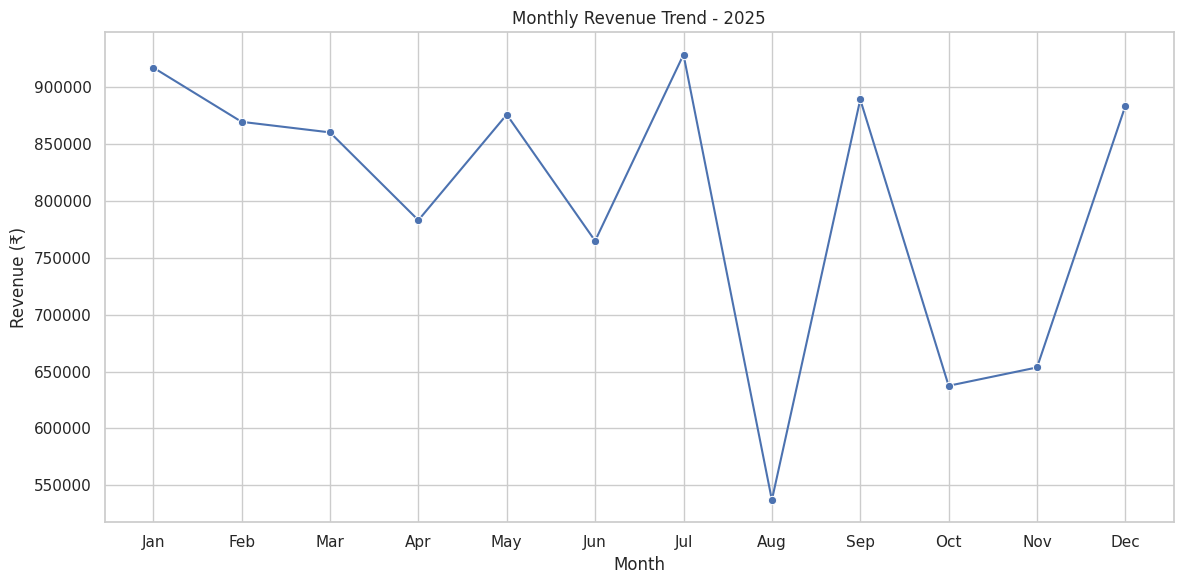

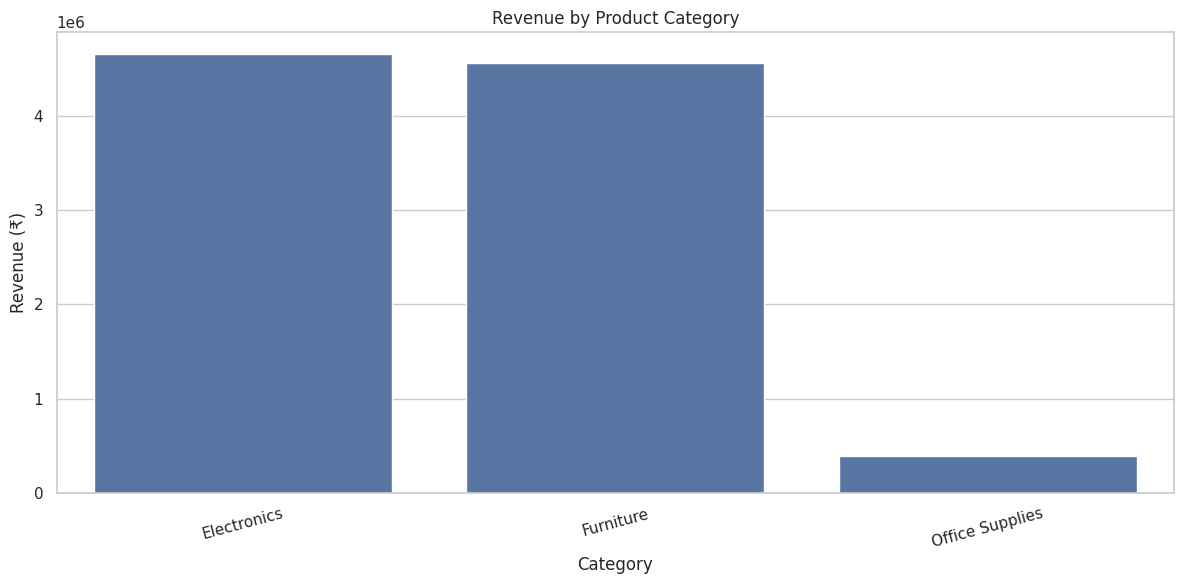

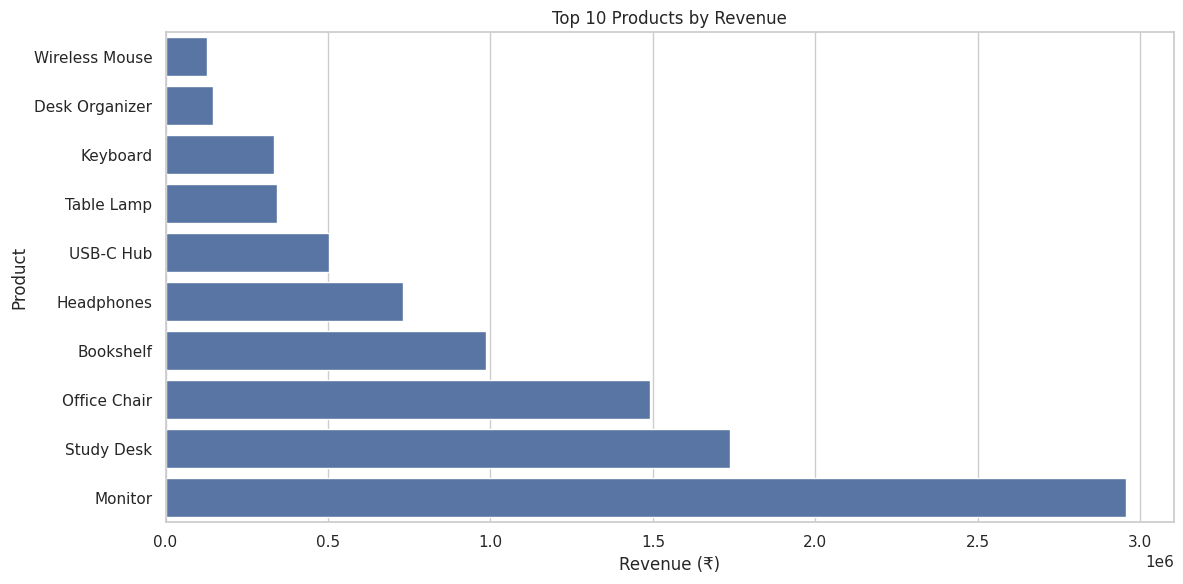

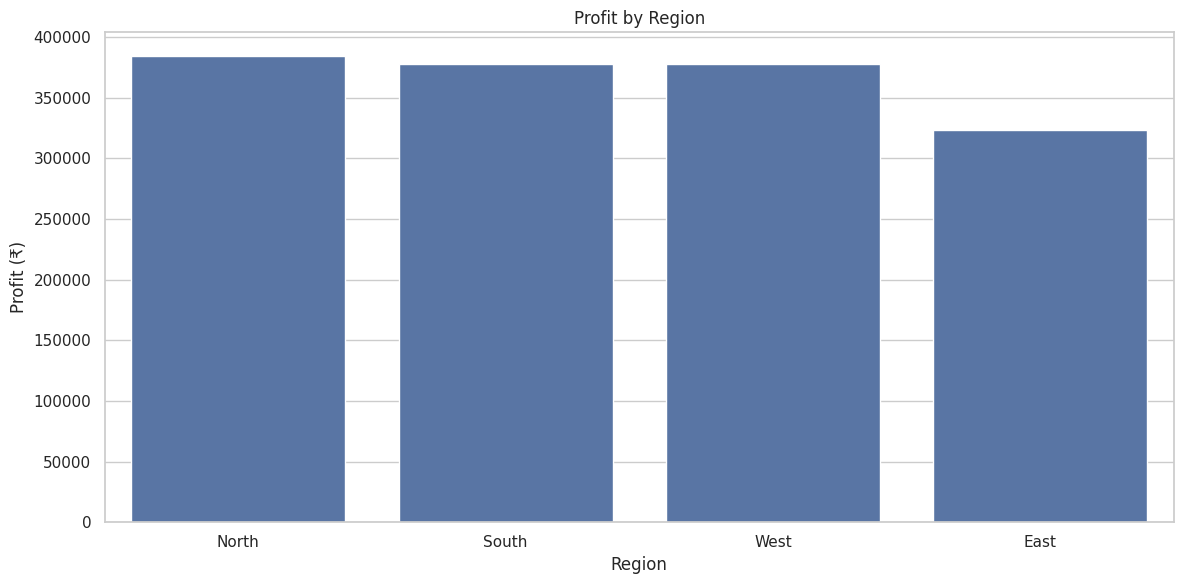

In [ ]:


import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)



plt.figure()

monthly_revenue = (
    df_clean.groupby(df_clean["Order Date"].dt.month)["Sales"].sum()
)

monthly_revenue.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()


plt.figure()

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()




plt.figure()

top_products = product_analysis.head(10).sort_values(
    by="Total_Revenue"
)

sns.barplot(
    x=top_products["Total_Revenue"],
    y=top_products.index
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (₹)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()




plt.figure()

sns.barplot(
    x=region_analysis.index,
    y=region_analysis["Total_Profit"]
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit (₹)")
plt.tight_layout()
plt.show()

In [ ]:


customer_analysis = df_clean.groupby("Customer ID").agg(
    Total_Spending=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values(
    by="Total_Spending",
    ascending=False
)

print("TOP 10 CUSTOMERS BY SPENDING")
display(customer_analysis.head(10).round(2))



product_margin = df_clean.groupby("Product").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum")
)

product_margin["Profit_Margin_%"] = (
    product_margin["Profit"] / product_margin["Revenue"]
) * 100

product_margin = product_margin.sort_values(
    by="Profit_Margin_%",
    ascending=False
)

print("\nPRODUCT PROFIT MARGINS")
display(product_margin.round(2))




discount_analysis = df_clean.groupby("Discount").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Revenue"]
) * 100

print("\nDISCOUNT ANALYSIS")
display(discount_analysis.round(2))




city_analysis = df_clean.groupby("City").agg(
    Total_Revenue=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).sort_values(
    by="Total_Revenue",
    ascending=False
)

print("\nTOP 10 CITIES BY REVENUE")
display(city_analysis.head(10).round(2))



print("\nADVANCED BUSINESS FINDINGS")
print("-" * 50)

print(
    "Highest Spending Customer:",
    customer_analysis["Total_Spending"].idxmax()
)

print(
    "Highest Margin Product:",
    product_margin["Profit_Margin_%"].idxmax()
)

print(
    "Highest Revenue City:",
    city_analysis["Total_Revenue"].idxmax()
)

TOP 10 CUSTOMERS BY SPENDING


,Total_Spending,Total_Profit,Total_Orders
Customer ID,,,
CUST-0280,128836.65,19450.02,10
CUST-0004,122922.35,16171.20,6
CUST-0251,121935.85,16405.29,6
CUST-0120,117235.15,12167.93,6
CUST-0143,114366.00,16273.79,9
CUST-0221,112415.05,15916.81,6
CUST-0119,112116.15,19487.29,7
CUST-0228,111964.25,13910.84,6
CUST-0050,110550.80,16399.36,8



PRODUCT PROFIT MARGINS


,Revenue,Profit,Profit_Margin_%
Product,,,
Pen Set,31692.30,10705.35,33.78
Stapler,51531.05,16467.44,31.96
Notebook Pack,65765.05,18889.58,28.72
Desk Organizer,147384.15,39455.09,26.77
Table Lamp,344395.25,89058.40,25.86
USB-C Hub,502950.15,121700.90,24.20
Wireless Mouse,127826.60,27985.70,21.89
Printer Paper,94443.30,18396.51,19.48
Keyboard,333843.00,64911.02,19.44



DISCOUNT ANALYSIS


,Total_Revenue,Total_Profit,Total_Orders,Profit_Margin_%
Discount,,,,
0.00,3265920.00,609708.07,377,18.67
0.05,1962877.65,316000.39,231,16.10
0.10,2298772.80,316394.53,297,13.76
0.15,1273576.25,146340.40,175,11.49
0.20,800652.80,75075.64,120,9.38



TOP 10 CITIES BY REVENUE


,Total_Revenue,Total_Profit,Total_Orders
City,,,
Kochi,803971.25,109934.75,75
Hyderabad,797785.60,118169.48,84
Mumbai,773992.70,119950.03,77
Patna,746628.45,110098.75,84
Chandigarh,723837.35,110115.62,80
Ahmedabad,720468.15,111765.17,76
Jaipur,652125.95,94080.03,75
Lucknow,598270.40,90459.53,74
Delhi,590156.45,90064.74,78



ADVANCED BUSINESS FINDINGS
--------------------------------------------------
Highest Spending Customer: CUST-0280
Highest Margin Product: Pen Set
Highest Revenue City: Kochi


In [ ]:


print("=" * 65)
print("       RETAIL SALES INTELLIGENCE - BUSINESS REPORT")
print("=" * 65)

print("\n1. CUSTOMER RETENTION")
print("-" * 65)
print(f"Highest spending customer: {customer_analysis['Total_Spending'].idxmax()}")
print(f"Top 10 customer revenue: ₹{customer_analysis.head(10)['Total_Spending'].sum():,.2f}")

top10_share = (
    customer_analysis.head(10)["Total_Spending"].sum()
    / total_revenue
) * 100

print(f"Top 10 customer revenue contribution: {top10_share:.2f}%")
print("Recommendation: Develop targeted customer retention strategies.")

print("\n2. PRODUCT PROFITABILITY")
print("-" * 65)
print(f"Highest margin product: {product_margin['Profit_Margin_%'].idxmax()}")
print(f"Highest total profit product: {product_analysis['Total_Profit'].idxmax()}")
print("Recommendation: Promote high-margin products and review low-margin pricing.")

print("\n3. DISCOUNT STRATEGY")
print("-" * 65)
print(discount_analysis[["Profit_Margin_%"]].round(2))
print("Recommendation: Evaluate discount effectiveness before increasing promotions.")

print("\n4. REGIONAL AND CITY PERFORMANCE")
print("-" * 65)
print(f"Highest revenue region: {region_analysis['Total_Revenue'].idxmax()}")
print(f"Highest revenue city: {city_analysis['Total_Revenue'].idxmax()}")
print("Recommendation: Investigate successful markets and replicate effective strategies.")

print("\n5. MONTHLY PERFORMANCE")
print("-" * 65)
print(f"Best revenue month: {monthly_analysis['Total_Revenue'].idxmax()}")
print(f"Weakest revenue month: {monthly_analysis['Total_Revenue'].idxmin()}")
print("Recommendation: Investigate monthly fluctuations and plan seasonal campaigns.")

print("\n" + "=" * 65)
print("END OF BUSINESS REPORT")
print("=" * 65)

       RETAIL SALES INTELLIGENCE - BUSINESS REPORT

1. CUSTOMER RETENTION
-----------------------------------------------------------------
Highest spending customer: CUST-0280
Top 10 customer revenue: ₹1,161,228.25
Top 10 customer revenue contribution: 12.09%
Recommendation: Develop targeted customer retention strategies.

2. PRODUCT PROFITABILITY
-----------------------------------------------------------------
Highest margin product: Pen Set
Highest total profit product: Monitor
Recommendation: Promote high-margin products and review low-margin pricing.

3. DISCOUNT STRATEGY
-----------------------------------------------------------------
          Profit_Margin_%
Discount                 
0.00                18.67
0.05                16.10
0.10                13.76
0.15                11.49
0.20                 9.38
Recommendation: Evaluate discount effectiveness before increasing promotions.

4. REGIONAL AND CITY PERFORMANCE
-------------------------------------------------------

In [ ]:


import os
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



export_dir = "Retail_Sales_Project"
charts_dir = os.path.join(export_dir, "charts")

os.makedirs(charts_dir, exist_ok=True)



df_clean.to_csv(
    os.path.join(export_dir, "cleaned_retail_dataset.csv"),
    index=False
)



kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Total Orders",
        "Average Order Value",
        "Profit Margin (%)",
        "Units Sold",
        "Unique Customers",
        "Average Discount (%)"
    ],
    "Value": [
        total_revenue,
        total_profit,
        total_orders,
        average_order_value,
        profit_margin,
        total_units_sold,
        unique_customers,
        average_discount
    ]
})

kpi_summary.to_csv(
    os.path.join(export_dir, "business_kpis.csv"),
    index=False
)



analysis_tables = {
    "product_analysis": product_analysis,
    "category_analysis": category_analysis,
    "region_analysis": region_analysis,
    "monthly_analysis": monthly_analysis,
    "customer_analysis": customer_analysis,
    "product_margins": product_margin,
    "discount_analysis": discount_analysis,
    "city_analysis": city_analysis
}

for name, table in analysis_tables.items():
    table.to_csv(
        os.path.join(export_dir, f"{name}.csv")
    )


sns.set_theme(style="whitegrid")


plt.figure(figsize=(12, 6))

sns.lineplot(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.tight_layout()

plt.savefig(
    os.path.join(charts_dir, "monthly_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()



plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_analysis.index,
    y=category_analysis["Total_Revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(charts_dir, "category_revenue.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()



plt.figure(figsize=(12, 7))

top_products = product_analysis.head(10).sort_values(
    by="Total_Revenue"
)

sns.barplot(
    x=top_products["Total_Revenue"],
    y=top_products.index
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (INR)")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    os.path.join(charts_dir, "top_products.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()


plt.figure(figsize=(10, 6))

sns.barplot(
    x=region_analysis.index,
    y=region_analysis["Total_Profit"]
)

plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit (INR)")
plt.tight_layout()

plt.savefig(
    os.path.join(charts_dir, "regional_profit.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()



excel_path = os.path.join(
    export_dir,
    "Retail_Sales_Analysis.xlsx"
)

with pd.ExcelWriter(excel_path) as writer:

    kpi_summary.to_excel(
        writer,
        sheet_name="KPIs",
        index=False
    )

    for name, table in analysis_tables.items():
        table.to_excel(
            writer,
            sheet_name=name[:31]
        )

report = """
RETAIL SALES INTELLIGENCE PROJECT
BUSINESS ANALYSIS REPORT

Dataset:
Synthetic retail transaction dataset
Period: January 2025 - December 2025

KEY BUSINESS KPIs

Total Revenue: Rs. {:,.2f}
Total Profit: Rs. {:,.2f}
Total Orders: {:,}
Average Order Value: Rs. {:,.2f}
Profit Margin: {:.2f}%
Units Sold: {:,}
Unique Customers: {:,}
Average Discount: {:.2f}%

BUSINESS FINDINGS

1. CUSTOMER RETENTION
Highest spending customer: {}
Top 10 customer revenue contribution: {:.2f}%

2. PRODUCT PROFITABILITY
Highest margin product: {}
Highest total profit product: {}

3. DISCOUNT STRATEGY
Profit margin decreases from {:.2f}% at zero discount
to {:.2f}% at a 20% discount.

4. REGIONAL AND CITY PERFORMANCE
Highest revenue region: {}
Highest revenue city: {}

5. MONTHLY PERFORMANCE
Best revenue month: {}
Weakest revenue month: {}

RECOMMENDATIONS

- Develop targeted customer retention strategies.
- Promote high-margin products.
- Review pricing and costs of lower-margin products.
- Evaluate discount effectiveness.
- Investigate regional and city-level opportunities.
- Investigate monthly revenue fluctuations.

NOTE:
The dataset is simulated and does not represent
actual financial records of a retail company.
""".format(
    total_revenue,
    total_profit,
    total_orders,
    average_order_value,
    profit_margin,
    total_units_sold,
    unique_customers,
    average_discount,
    customer_analysis["Total_Spending"].idxmax(),
    top10_share,
    product_margin["Profit_Margin_%"].idxmax(),
    product_analysis["Total_Profit"].idxmax(),
    discount_analysis.loc[0.00, "Profit_Margin_%"],
    discount_analysis.loc[0.20, "Profit_Margin_%"],
    region_analysis["Total_Revenue"].idxmax(),
    city_analysis["Total_Revenue"].idxmax(),
    monthly_analysis["Total_Revenue"].idxmax(),
    monthly_analysis["Total_Revenue"].idxmin()
)

with open(
    os.path.join(export_dir, "Business_Recommendations.txt"),
    "w",
    encoding="utf-8"
) as file:
    file.write(report)


zip_path = shutil.make_archive(
    "Retail_Sales_Project",
    "zip",
    root_dir=export_dir
)


print("PROJECT EXPORT COMPLETED!")
print("-" * 50)

for root, folders, files_list in os.walk(export_dir):
    for filename in files_list:
        print(os.path.join(root, filename))

print("\nZIP PACKAGE:", zip_path)

from google.colab import files
files.download(zip_path)

PROJECT EXPORT COMPLETED!
--------------------------------------------------
Retail_Sales_Project/product_margins.csv
Retail_Sales_Project/product_analysis.csv
Retail_Sales_Project/Business_Recommendations.txt
Retail_Sales_Project/customer_analysis.csv
Retail_Sales_Project/discount_analysis.csv
Retail_Sales_Project/monthly_analysis.csv
Retail_Sales_Project/business_kpis.csv
Retail_Sales_Project/region_analysis.csv
Retail_Sales_Project/Retail_Sales_Analysis.xlsx
Retail_Sales_Project/city_analysis.csv
Retail_Sales_Project/cleaned_retail_dataset.csv
Retail_Sales_Project/category_analysis.csv
Retail_Sales_Project/charts/regional_profit.png
Retail_Sales_Project/charts/top_products.png
Retail_Sales_Project/charts/category_revenue.png
Retail_Sales_Project/charts/monthly_revenue.png

ZIP PACKAGE: /content/Retail_Sales_Project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>